In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns

In [ ]:
vocab_size = 10000

max_length = 200

(X_train, y_train), (X_test, y_test) = keras.datasets.imdb.load_data(
    num_words=vocab_size
)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("First Review Sequence:", X_train[0])
print("First Label:", y_train[0])

Training Samples: 25000
Testing Samples: 25000
First Review Sequence: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 19,

In [ ]:
sequence_lengths = [len(sequence) for sequence in X_train]

print("Minimum Length:", min(sequence_lengths))
print("Maximum Length:", max(sequence_lengths))
print("Average Length:", np.mean(sequence_lengths))

Minimum Length: 11
Maximum Length: 2494
Average Length: 238.71364


In [ ]:
X_train = keras.utils.pad_sequences(
    X_train,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test = keras.utils.pad_sequences(
    X_test,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)

X_train Shape: (25000, 200)
X_test Shape: (25000, 200)


Negative Reviews: 12500
Positive Reviews: 12500


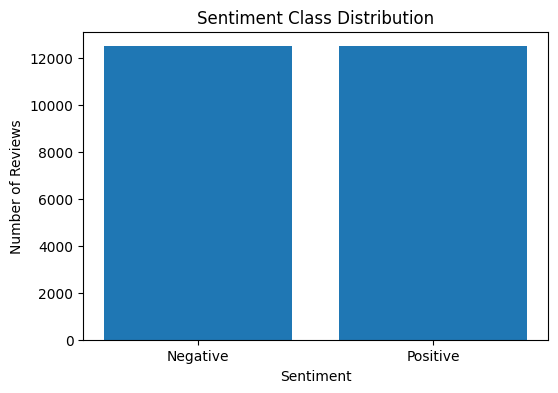

In [ ]:
print("Negative Reviews:", np.sum(y_train == 0))
print("Positive Reviews:", np.sum(y_train == 1))

plt.figure(figsize=(6, 4))

plt.bar(
    ["Negative", "Positive"],
    [
        np.sum(y_train == 0),
        np.sum(y_train == 1)
    ]
)

plt.title("Sentiment Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

In [ ]:
def create_rnn_model():
    model = keras.Sequential([
        layers.Embedding(vocab_size, 64, input_length=max_length),
        layers.SimpleRNN(64),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [ ]:
def create_lstm_model():
    model = keras.Sequential([
        layers.Embedding(vocab_size, 64, input_length=max_length),
        layers.LSTM(64),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [ ]:
def create_gru_model():
    model = keras.Sequential([
        layers.Embedding(vocab_size, 64, input_length=max_length),
        layers.GRU(64),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [ ]:
rnn_model = create_rnn_model()
rnn_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
lstm_model = create_lstm_model()
lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
gru_model = create_gru_model()
gru_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
rnn_history = rnn_model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=3,
    batch_size=64,
    verbose=1
)

Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 23s 74ms/step - accuracy: 0.7394 - loss: 0.3900 - val_accuracy: 0.5018 - val_loss: 0.9832
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 21s 67ms/step - accuracy: 0.7546 - loss: 0.3643 - val_accuracy: 0.5058 - val_loss: 1.0771
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 26s 82ms/step - accuracy: 0.7659 - loss: 0.3514 - val_accuracy: 0.4992 - val_loss: 1.1059


In [ ]:
lstm_history = lstm_model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=3,
    batch_size=64,
    verbose=1
)

Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 80s 247ms/step - accuracy: 0.5200 - loss: 0.6914 - val_accuracy: 0.5332 - val_loss: 0.6872
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 47s 151ms/step - accuracy: 0.6029 - loss: 0.6440 - val_accuracy: 0.6082 - val_loss: 0.6482
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 48s 155ms/step - accuracy: 0.7010 - loss: 0.5422 - val_accuracy: 0.5480 - val_loss: 0.6784


In [ ]:
gru_history = gru_model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=3,
    batch_size=64,
    verbose=1
)

Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 59s 181ms/step - accuracy: 0.5274 - loss: 0.6901 - val_accuracy: 0.5514 - val_loss: 0.6774
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 80s 174ms/step - accuracy: 0.6186 - loss: 0.6447 - val_accuracy: 0.8034 - val_loss: 0.5167
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 174ms/step - accuracy: 0.8627 - loss: 0.3392 - val_accuracy: 0.8592 - val_loss: 0.3383


In [ ]:
rnn_loss, rnn_accuracy = rnn_model.evaluate(X_test, y_test)

lstm_loss, lstm_accuracy = lstm_model.evaluate(X_test, y_test)

gru_loss, gru_accuracy = gru_model.evaluate(X_test, y_test)

print("RNN Accuracy:", rnn_accuracy)
print("LSTM Accuracy:", lstm_accuracy)
print("GRU Accuracy:", gru_accuracy)

782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.4974 - loss: 1.0860
782/782 ━━━━━━━━━━━━━━━━━━━━ 21s 26ms/step - accuracy: 0.5493 - loss: 0.6800
782/782 ━━━━━━━━━━━━━━━━━━━━ 20s 26ms/step - accuracy: 0.8572 - loss: 0.3391
RNN Accuracy: 0.4973599910736084
LSTM Accuracy: 0.5492799878120422
GRU Accuracy: 0.8571599721908569


In [ ]:
comparison = pd.DataFrame({
    "Model": ["RNN", "LSTM", "GRU"],
    "Test Loss": [rnn_loss, lstm_loss, gru_loss],
    "Test Accuracy": [
        rnn_accuracy,
        lstm_accuracy,
        gru_accuracy
    ]
})

comparison

,Model,Test Loss,Test Accuracy
0,RNN,1.085967,0.49736
1,LSTM,0.680018,0.54928
2,GRU,0.339061,0.85716


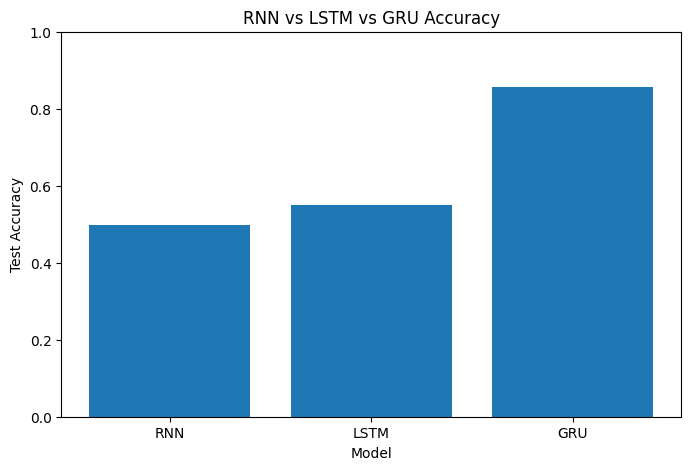

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Model"],
    comparison["Test Accuracy"]
)

plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.title("RNN vs LSTM vs GRU Accuracy")
plt.ylim(0, 1)
plt.show()

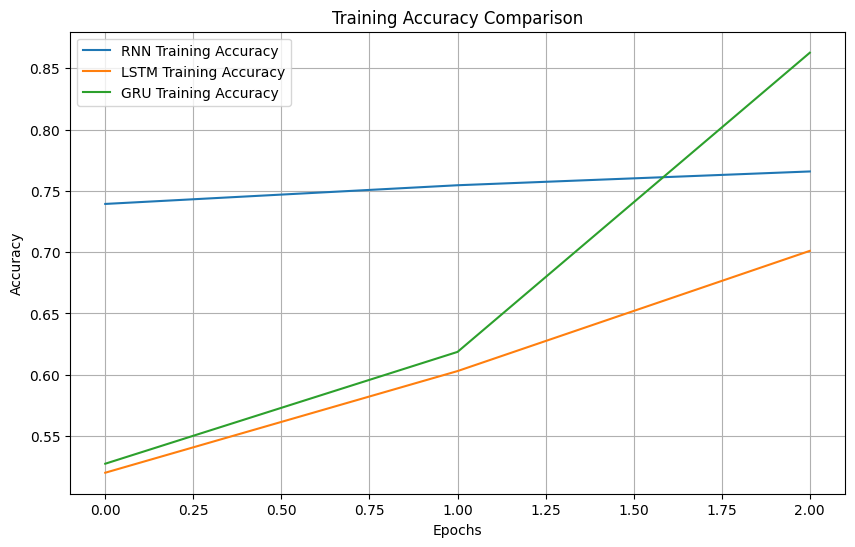

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    rnn_history.history["accuracy"],
    label="RNN Training Accuracy"
)

plt.plot(
    lstm_history.history["accuracy"],
    label="LSTM Training Accuracy"
)

plt.plot(
    gru_history.history["accuracy"],
    label="GRU Training Accuracy"
)

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training Accuracy Comparison")
plt.legend()
plt.grid(True)
plt.show()

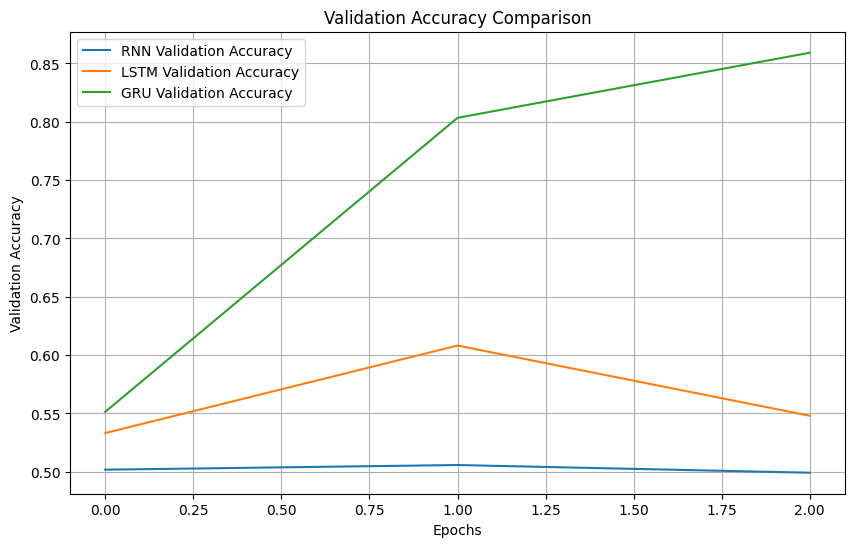

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    rnn_history.history["val_accuracy"],
    label="RNN Validation Accuracy"
)

plt.plot(
    lstm_history.history["val_accuracy"],
    label="LSTM Validation Accuracy"
)

plt.plot(
    gru_history.history["val_accuracy"],
    label="GRU Validation Accuracy"
)

plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy Comparison")
plt.legend()
plt.grid(True)
plt.show()

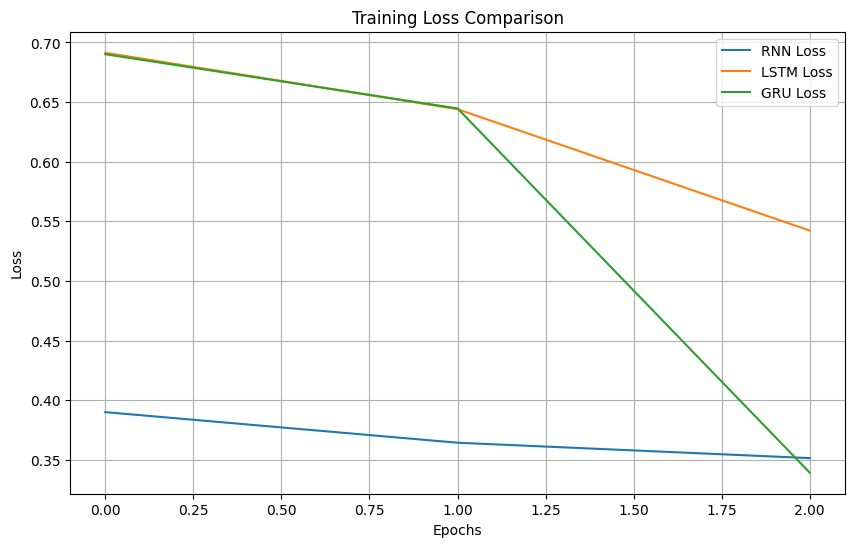

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    rnn_history.history["loss"],
    label="RNN Loss"
)

plt.plot(
    lstm_history.history["loss"],
    label="LSTM Loss"
)

plt.plot(
    gru_history.history["loss"],
    label="GRU Loss"
)

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Comparison")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
rnn_predictions = (
    rnn_model.predict(X_test) > 0.5
).astype("int32").flatten()

lstm_predictions = (
    lstm_model.predict(X_test) > 0.5
).astype("int32").flatten()

gru_predictions = (
    gru_model.predict(X_test) > 0.5
).astype("int32").flatten()

782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step
782/782 ━━━━━━━━━━━━━━━━━━━━ 22s 27ms/step
782/782 ━━━━━━━━━━━━━━━━━━━━ 19s 25ms/step


In [ ]:
print("RNN Classification Report")
print(
    classification_report(
        y_test,
        rnn_predictions,
        target_names=["Negative", "Positive"]
    )
)

print("LSTM Classification Report")
print(
    classification_report(
        y_test,
        lstm_predictions,
        target_names=["Negative", "Positive"]
    )
)

print("GRU Classification Report")
print(
    classification_report(
        y_test,
        gru_predictions,
        target_names=["Negative", "Positive"]
    )
)

RNN Classification Report
              precision    recall  f1-score   support

    Negative       0.50      0.72      0.59     12500
    Positive       0.50      0.27      0.35     12500

    accuracy                           0.50     25000
   macro avg       0.50      0.50      0.47     25000
weighted avg       0.50      0.50      0.47     25000

LSTM Classification Report
              precision    recall  f1-score   support

    Negative       0.64      0.22      0.33     12500
    Positive       0.53      0.88      0.66     12500

    accuracy                           0.55     25000
   macro avg       0.59      0.55      0.50     25000
weighted avg       0.59      0.55      0.50     25000

GRU Classification Report
              precision    recall  f1-score   support

    Negative       0.89      0.82      0.85     12500
    Positive       0.83      0.89      0.86     12500

    accuracy                           0.86     25000
   macro avg       0.86      0.86      0.86     2

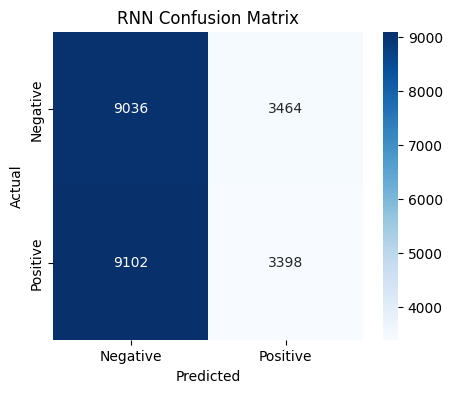

In [ ]:
cm_rnn = confusion_matrix(y_test, rnn_predictions)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_rnn,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("RNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

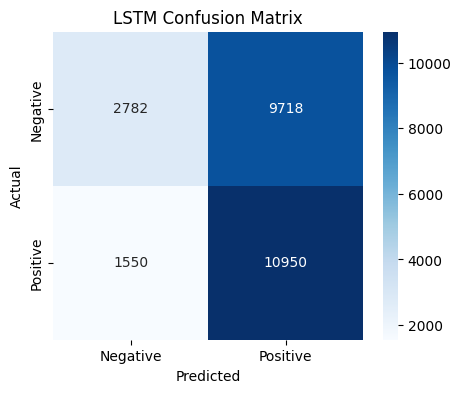

In [ ]:
cm_lstm = confusion_matrix(y_test, lstm_predictions)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_lstm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

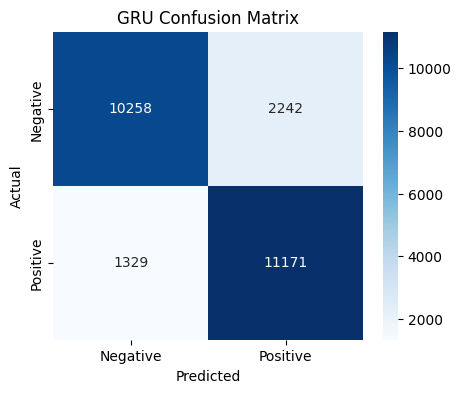

In [ ]:
cm_gru = confusion_matrix(y_test, gru_predictions)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_gru,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("GRU Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

metrics_comparison = pd.DataFrame({
    "Model": ["RNN", "LSTM", "GRU"],
    "Accuracy": [
        accuracy_score(y_test, rnn_predictions),
        accuracy_score(y_test, lstm_predictions),
        accuracy_score(y_test, gru_predictions)
    ],
    "Precision": [
        precision_score(y_test, rnn_predictions),
        precision_score(y_test, lstm_predictions),
        precision_score(y_test, gru_predictions)
    ],
    "Recall": [
        recall_score(y_test, rnn_predictions),
        recall_score(y_test, lstm_predictions),
        recall_score(y_test, gru_predictions)
    ],
    "F1 Score": [
        f1_score(y_test, rnn_predictions),
        f1_score(y_test, lstm_predictions),
        f1_score(y_test, gru_predictions)
    ]
})

metrics_comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,RNN,0.49736,0.495191,0.27184,0.350997
1,LSTM,0.54928,0.529805,0.87600,0.660275
2,GRU,0.85716,0.832849,0.89368,0.862193


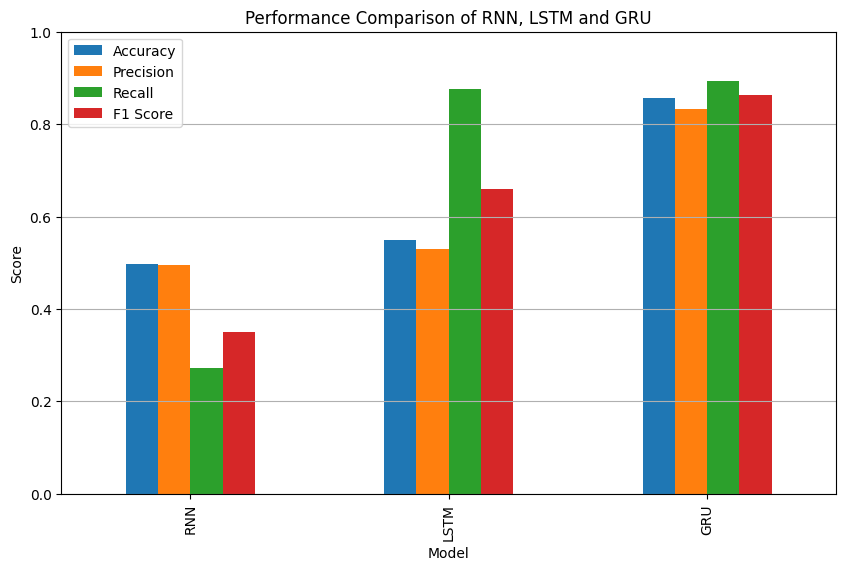

In [ ]:
metrics_comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Performance Comparison of RNN, LSTM and GRU")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y")
plt.show()

In [ ]:
best_model = comparison.loc[
    comparison["Test Accuracy"].idxmax(),
    "Model"
]

print("The RNN, LSTM and GRU models were implemented for sentiment classification.")
print("All models were evaluated using accuracy, precision, recall and F1-score.")
print("The best-performing model was:", best_model)
print("LSTM and GRU generally handle long-term dependencies better than Simple RNN.")
print("GRU has fewer gates and parameters than LSTM, making it computationally efficient.")

The RNN, LSTM and GRU models were implemented for sentiment classification.
All models were evaluated using accuracy, precision, recall and F1-score.
The best-performing model was: GRU
LSTM and GRU generally handle long-term dependencies better than Simple RNN.
GRU has fewer gates and parameters than LSTM, making it computationally efficient.
